<a href="https://colab.research.google.com/github/fathimanoorjahan03-afk/ROADSHIELD/blob/main/RoadShield_Hotspot_Satellite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Install required libraries
!pip -q install folium scikit-learn pyproj branca

# Import libraries
import pandas as pd
import numpy as np

import folium          #map leaflet to visualize
import branca.colormap as cm #help follium to give color
from folium.plugins import HeatMap

from sklearn.cluster import DBSCAN
from pyproj import Transformer #translate longitude and latitude to distance metrics

from IPython.display import display
import matplotlib.pyplot as plt

import warnings   #controlls the warning msgs
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Main project /raw_data/road_collision_2023_2025.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (306710, 44)


In [ ]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306710 entries, 0 to 306709
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   306710 non-null  object 
 1   collision_year                                    306710 non-null  int64  
 2   collision_ref_no                                  306710 non-null  object 
 3   location_easting_osgr                             306696 non-null  float64
 4   location_northing_osgr                            306696 non-null  float64
 5   longitude                                         306696 non-null  float64
 6   latitude                                          306696 non-null  float64
 7   police_force                                      306710 non-null  int64  
 8   collision_severity                                306710 non-n

In [ ]:
print("\nNumerical Statistical Summary:")
display(df.describe())


Numerical Statistical Summary:


,collision_year,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,day_of_week,local_authority_district,first_road_class,first_road_number,road_type,speed_limit,junction_detail_historic,junction_detail,junction_control,second_road_class,second_road_number,pedestrian_crossing_human_control_historic,pedestrian_crossing_physical_facilities_historic,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
count,"306,710.00","306,696.00","306,696.00","306,696.00","306,696.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00","306,710.00"
mean,"2,023.99","454,376.74","276,406.06",-1.22,52.38,27.82,2.74,1.82,1.27,4.13,-1.00,4.24,790.71,5.26,35.84,2.27,7.36,1.75,3.68,242.05,-0.16,0.27,5.51,2.03,1.66,1.40,-0.24,-0.27,2.77,1.33,1.52,1.72,2.22,0.66,0.24,0.74
std,0.82,"92,567.95","146,113.82",1.35,1.32,24.20,0.47,0.69,0.75,1.93,0.00,1.47,"1,585.65",1.70,14.51,12.24,9.83,2.59,2.70,975.23,1.81,2.33,16.23,1.70,1.85,1.11,1.57,1.49,14.71,0.47,0.82,0.79,2.64,0.47,0.42,0.43
min,"2,023.00","70,537.00","10,211.00",-7.43,49.91,1.00,1.00,1.00,1.00,1.00,-1.00,-1.00,-1.00,1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,1.00,-1.00,-1.00,-1.00,-1.00,-1.00,1.00,-1.00,-1.00,0.00,0.00,0.00
25%,"2,023.00","392,459.75","175,223.75",-2.11,51.46,5.00,3.00,1.00,1.00,2.00,-1.00,3.00,0.00,6.00,30.00,-1.00,0.00,-1.00,0.00,-1.00,-1.00,-1.00,0.00,1.00,1.00,1.00,-1.00,-1.00,0.00,1.00,1.00,2.00,-1.00,0.00,0.00,0.31
50%,"2,024.00","459,313.00","221,292.00",-1.12,51.87,22.00,3.00,2.00,1.00,4.00,-1.00,4.00,30.00,6.00,30.00,0.00,0.00,2.00,6.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00,1.00,1.00,2.00,3.00,1.00,0.00,1.00
75%,"2,025.00","529,229.00","382,951.50",-0.14,53.34,45.00,3.00,2.00,1.00,6.00,-1.00,6.00,547.00,6.00,40.00,3.00,13.00,4.00,6.00,0.00,0.00,0.00,0.00,4.00,1.00,2.00,0.00,0.00,0.00,2.00,2.00,2.00,3.00,1.00,0.16,1.00
max,"2,025.00","655,160.00","1,162,591.00",1.76,60.35,99.00,3.00,26.00,142.00,7.00,-1.00,6.00,"9,999.00",9.00,70.00,99.00,99.00,9.00,9.00,"9,999.00",9.00,9.00,99.00,7.00,9.00,9.00,9.00,9.00,99.00,3.00,3.00,2.00,7.00,1.00,1.00,1.00


In [ ]:
print("\nCategorical Statistical Summary:")
display(df.describe(include='object'))


Categorical Statistical Summary:


,collision_index,collision_ref_no,date,time,local_authority_ons_district,local_authority_highway,local_authority_highway_current,lsoa_of_accident_location
count,306710,306710,306710,306710,306710,306710,306710,306710
unique,306710,304106,1096,1440,353,210,208,34377
top,2023170M20483,340WN4702,01/12/2023,17:00,E08000025,E10000016,E10000016,-1
freq,1,3,428,2949,6802,9227,9227,12520


In [ ]:
print("\nColumn Data Types:")
display(df.dtypes)


Column Data Types:


,0
collision_index,object
collision_year,int64
collision_ref_no,object
location_easting_osgr,float64
location_northing_osgr,float64
longitude,float64
latitude,float64
police_force,int64
collision_severity,int64
number_of_vehicles,int64


In [ ]:
#Check missing values in each column

missing_values = df.isnull().sum()



In [ ]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100


In [ ]:
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

In [ ]:
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

print("Missing Values Analysis:")
display(missing_summary)

Missing Values Analysis:


,Missing Values,Missing Percentage
location_easting_osgr,14,0.00
location_northing_osgr,14,0.00
longitude,14,0.00
latitude,14,0.00


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

minus_one_counts = (df[numeric_cols] == -1).sum()

minus_one_summary = minus_one_counts[
    minus_one_counts > 0
].sort_values(ascending=False)

print("\nColumns containing -1 values:")
display(minus_one_summary.to_frame(name='Count of -1 Values'))


Columns containing -1 values:


,Count of -1 Values
local_authority_district,306710
carriageway_hazards_historic,150279
special_conditions_at_site,150273
pedestrian_crossing_physical_facilities_historic,149939
pedestrian_crossing_human_control_historic,149939
junction_detail_historic,147474
junction_control,130863
enhanced_severity_collision,103548
second_road_number,92166
trunk_road_flag,21675


In [ ]:
#Check geographical coordinate quality


coordinates = df[['longitude', 'latitude']].apply(
    pd.to_numeric, errors='coerce'
)


In [ ]:
missing_coordinates = coordinates.isnull().any(axis=1)

In [ ]:
invalid_coordinates = (
    ~coordinates['longitude'].between(-8.5, 2.5) |
    ~coordinates['latitude'].between(49.5, 61.5)
)

print("\nGeographical Data Quality:")

print("Total records:", len(df))
print("Missing coordinate records:", missing_coordinates.sum())
print("Outside broad GB coordinate bounds:",
      invalid_coordinates.sum())

print("Potentially usable coordinate records:",
      (~missing_coordinates & ~invalid_coordinates).sum())


Geographical Data Quality:
Total records: 306710
Missing coordinate records: 14
Outside broad GB coordinate bounds: 14
Potentially usable coordinate records: 306696


In [ ]:

# CELL 5: Cleaning and Preparing Geographical Coordinates

# Step 1: Convert coordinate columns into numeric format
coordinate_columns = [
    'longitude',
    'latitude',
    'location_easting_osgr',
    'location_northing_osgr'
]

for col in coordinate_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')


# Step 2: Identify valid latitude and longitude
valid_latlon = (
    np.isfinite(df['longitude']) &
    np.isfinite(df['latitude']) &
    df['longitude'].between(-8.5, 2.5) &
    df['latitude'].between(49.5, 61.5)
)


# Step 3: Identify valid projected coordinates
valid_projected = (
    np.isfinite(df['location_easting_osgr']) &
    np.isfinite(df['location_northing_osgr']) &
    df['location_easting_osgr'].between(0, 700000) &
    df['location_northing_osgr'].between(0, 1300000)
)


# Step 4: Identify records suitable for grid analysis
valid_grid = valid_latlon & valid_projected


# Step 5: Display cleaning results
print("GEOGRAPHICAL DATA CLEANING RESULTS")

print("\nOriginal Dataset Records:", len(df))

print("Valid Mapping Records:", valid_latlon.sum())

print("Valid Grid Analysis Records:", valid_grid.sum())

print("Records with invalid mapping coordinates:",
      (~valid_latlon).sum())

print("Records with invalid grid coordinates:",
      (~valid_grid).sum())


# Step 6: Inspect valid mapping coordinates
print("\nValid Mapping Coordinates:")
display(
    df.loc[valid_latlon, ['longitude', 'latitude']].head()
)


# Step 7: Inspect valid projected coordinates
print("\nValid Projected Coordinates:")
display(
    df.loc[
        valid_grid,
        ['location_easting_osgr', 'location_northing_osgr']
    ].head()
)


GEOGRAPHICAL DATA CLEANING RESULTS

Original Dataset Records: 306710
Valid Mapping Records: 306696
Valid Grid Analysis Records: 306696
Records with invalid mapping coordinates: 14
Records with invalid grid coordinates: 14

Valid Mapping Coordinates:


,longitude,latitude
0,-1.21,54.57
1,-1.22,54.56
2,-1.33,54.56
3,-1.59,54.55
4,-2.58,53.43



Valid Projected Coordinates:


,location_easting_osgr,location_northing_osgr
0,"451,177.00","519,211.00"
1,"450,248.00","518,901.00"
2,"443,464.00","518,662.00"
3,"426,760.00","517,238.00"
4,"361,439.00","393,070.00"


In [ ]:
year_counts = (
    df.loc[valid_latlon]
    .groupby('collision_year')
    .size()
    .reset_index(name='collision_count')
)

print("Year-wise Collision Count:")
display(year_counts)


Year-wise Collision Count:


,collision_year,collision_count
0,2023,104246
1,2024,100927
2,2025,101523


In [ ]:
severity_counts = (
    df.loc[valid_latlon, 'collision_severity']
    .value_counts()
    .sort_index()
    .reset_index()
)
severity_counts.columns = [
    'collision_severity',
    'collision_count'
]

print("\nCollision Severity Distribution:")
display(severity_counts)


Collision Severity Distribution:


,collision_severity,collision_count
0,1,4477
1,2,72191
2,3,230028


In [ ]:
severity_year = pd.crosstab(
    df.loc[valid_latlon, 'collision_year'],
    df.loc[valid_latlon, 'collision_severity']
)

print("\nYear-wise Severity Comparison:")
display(severity_year)


Year-wise Severity Comparison:


collision_severity,1,2,3
collision_year,,,
2023,1522,23434,79290
2024,1502,23567,75858
2025,1453,25190,74880


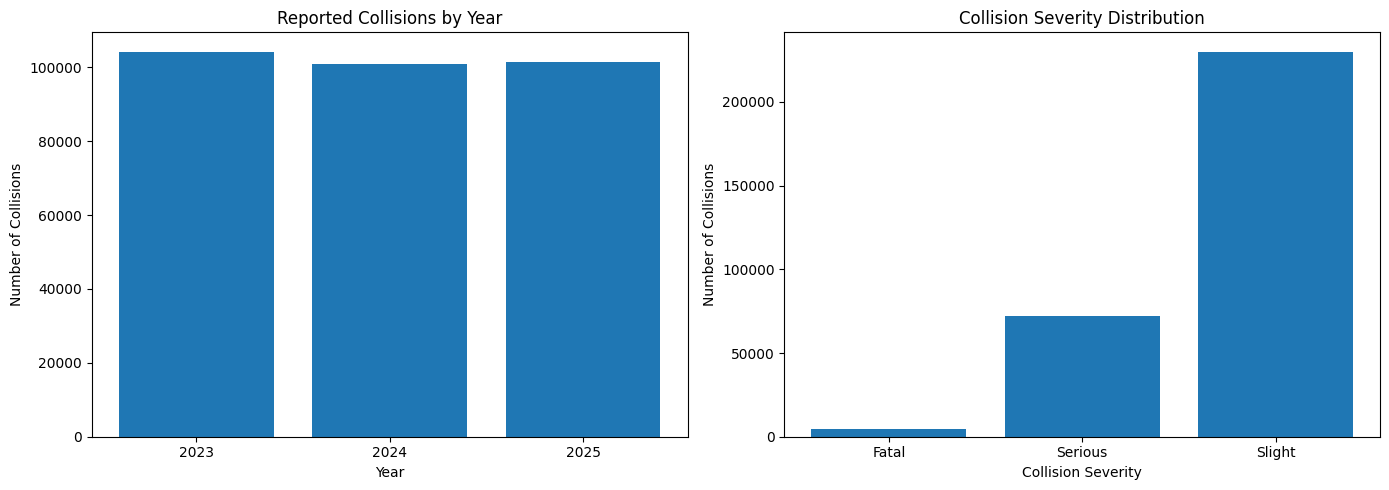

In [ ]:

# Combined visualization: Year-wise and Severity analysis

# Create severity labels
severity_labels = {
    1: 'Fatal',
    2: 'Serious',
    3: 'Slight'
}

severity_plot = severity_counts.copy()

severity_plot['severity_label'] = (
    severity_plot['collision_severity']
    .map(severity_labels)
)

# Create two graphs together
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graph 1: Year-wise collisions
axes[0].bar(
    year_counts['collision_year'].astype(str),
    year_counts['collision_count']
)

axes[0].set_title('Reported Collisions by Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Collisions')

# Graph 2: Severity distribution
axes[1].bar(
    severity_plot['severity_label'],
    severity_plot['collision_count']
)

axes[1].set_title('Collision Severity Distribution')
axes[1].set_xlabel('Collision Severity')
axes[1].set_ylabel('Number of Collisions')

# Adjust layout and display
fig.tight_layout()
plt.show()


In [ ]:
axes[1].bar(
    severity_counts['collision_severity'].astype(str),
    severity_counts['collision_count']
)

axes[1].set_title('Collision Severity Distribution')
axes[1].set_xlabel('Severity Code')
axes[1].set_ylabel('Number of Collisions')

plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

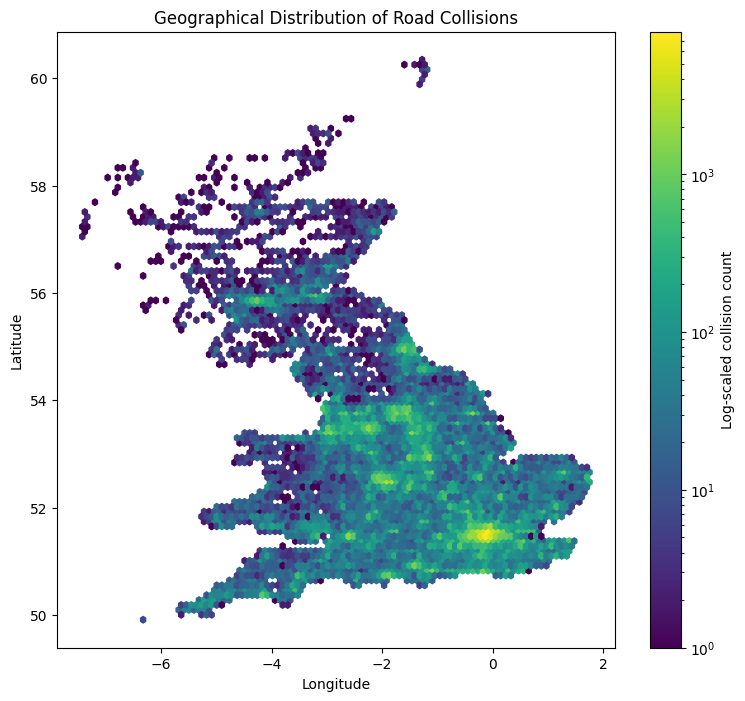

In [ ]:
plt.figure(figsize=(9, 8))

heatmap = plt.hexbin(
    df.loc[valid_latlon, 'longitude'],
    df.loc[valid_latlon, 'latitude'],
    gridsize=100,
    mincnt=1,
    bins='log'
)

plt.colorbar(heatmap, label='Log-scaled collision count')
plt.title('Geographical Distribution of Road Collisions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()


In [ ]:
# Create grid coordinates using British National Grid

df['grid_easting_1km'] = (
    np.floor(df['location_easting_osgr'] / 1000) * 1000
).astype('Int64')

df['grid_northing_1km'] = (
    np.floor(df['location_northing_osgr'] / 1000) * 1000
).astype('Int64')


In [ ]:
#Group accident records into geographical grid cells


grid_summary = (
    df.loc[valid_grid]
    .groupby(['grid_easting_1km', 'grid_northing_1km'])
    .size()
    .reset_index(name='collision_count')
)


In [ ]:
# Calculate geographical centre of each grid cell

grid_summary['center_easting'] = (
    grid_summary['grid_easting_1km'] + 500
)

grid_summary['center_northing'] = (
    grid_summary['grid_northing_1km'] + 500
)

In [ ]:
#Sort grid cells by accident frequency

grid_summary = grid_summary.sort_values(
    by='collision_count',
    ascending=False
).reset_index(drop=True)

In [ ]:
print("GEOGRAPHICAL GRID ANALYSIS")

print("\nGrid cell size: 1 km x 1 km")

print("Total occupied grid cells:", len(grid_summary))

print("Total collisions assigned:",
      grid_summary['collision_count'].sum())

print("Highest collision count in one grid cell:",
      grid_summary['collision_count'].max())

GEOGRAPHICAL GRID ANALYSIS

Grid cell size: 1 km x 1 km
Total occupied grid cells: 54439
Total collisions assigned: 306696
Highest collision count in one grid cell: 346


In [ ]:
print("\nTop 10 Grid Cells by Collision Count:")

display(grid_summary.head(10))


Top 10 Grid Cells by Collision Count:


,grid_easting_1km,grid_northing_1km,collision_count,center_easting,center_northing
0,534000,181000,346,534500,181500
1,529000,180000,328,529500,180500
2,529000,181000,313,529500,181500
3,527000,181000,304,527500,181500
4,533000,182000,284,533500,182500
5,527000,171000,253,527500,171500
6,528000,181000,243,528500,181500
7,531000,175000,237,531500,175500
8,533000,181000,237,533500,181500
9,530000,181000,234,530500,181500


In [ ]:
# Step 1: Calculate the 99th percentile threshold
hotspot_threshold = grid_summary['collision_count'].quantile(0.99)

print("99th Percentile Collision Threshold:",
      hotspot_threshold)

99th Percentile Collision Threshold: 59.0


In [ ]:
# Step 2: Identify candidate hotspot cells
hotspot_cells = grid_summary.loc[
    grid_summary['collision_count'] >= hotspot_threshold
]


In [ ]:
 #Step 3: Calculate hotspot statistics
total_grid_cells = len(grid_summary)

total_collisions = grid_summary['collision_count'].sum()

hotspot_grid_count = len(hotspot_cells)

hotspot_collision_count = hotspot_cells['collision_count'].sum()

In [ ]:
# Step 4: Calculate percentages
hotspot_grid_percentage = (
    hotspot_grid_count / total_grid_cells
) * 100

hotspot_collision_percentage = (
    hotspot_collision_count / total_collisions
) * 100

In [ ]:
# Step 5: Display findings
print("\nHOTSPOT IDENTIFICATION RESULTS")

print("Total occupied grid cells:", total_grid_cells)

print("Candidate hotspot cells:", hotspot_grid_count)

print("Percentage of hotspot grid cells:",
      round(hotspot_grid_percentage, 2), "%")

print("Total collisions in hotspot cells:",
      hotspot_collision_count)

print("Percentage of collisions in hotspot cells:",
      round(hotspot_collision_percentage, 2), "%")

print("Average collisions per occupied grid cell:",
      round(grid_summary['collision_count'].mean(), 2))

print("Average collisions per hotspot cell:",
      round(hotspot_cells['collision_count'].mean(), 2))


HOTSPOT IDENTIFICATION RESULTS
Total occupied grid cells: 54439
Candidate hotspot cells: 546
Percentage of hotspot grid cells: 1.0 %
Total collisions in hotspot cells: 54078
Percentage of collisions in hotspot cells: 17.63 %
Average collisions per occupied grid cell: 5.63
Average collisions per hotspot cell: 99.04


In [ ]:
print("\nTOP 10 CANDIDATE HOTSPOTS")

display(hotspot_cells.head(10))



TOP 10 CANDIDATE HOTSPOTS


,grid_easting_1km,grid_northing_1km,collision_count,center_easting,center_northing
0,534000,181000,346,534500,181500
1,529000,180000,328,529500,180500
2,529000,181000,313,529500,181500
3,527000,181000,304,527500,181500
4,533000,182000,284,533500,182500
5,527000,171000,253,527500,171500
6,528000,181000,243,528500,181500
7,531000,175000,237,531500,175500
8,533000,181000,237,533500,181500
9,530000,181000,234,530500,181500


In [ ]:

print("99th Percentile Threshold:", hotspot_threshold)

print("Total Grid Cells:", total_grid_cells)

print("Candidate Hotspot Cells:", hotspot_grid_count)

print("Hotspot Grid Percentage:", round(hotspot_grid_percentage, 2), "%")

print("Collisions in Hotspot Cells:", hotspot_collision_count)

print("Collision Percentage in Hotspots:", round(hotspot_collision_percentage, 2), "%")


99th Percentile Threshold: 59.0
Total Grid Cells: 54439
Candidate Hotspot Cells: 546
Hotspot Grid Percentage: 1.0 %
Collisions in Hotspot Cells: 54078
Collision Percentage in Hotspots: 17.63 %


In [ ]:

# CELL 9: Convert Grid Coordinates into Latitude and Longitude

# Step 1: Create coordinate transformer
transformer = Transformer.from_crs(
    "EPSG:27700",
    "EPSG:4326",
    always_xy=True
)

# Step 2: Convert centre coordinates of hotspot cells

hotspot_cells = hotspot_cells.copy()

hotspot_cells['center_longitude'], hotspot_cells['center_latitude'] = (
    transformer.transform(
        hotspot_cells['center_easting'].values,
        hotspot_cells['center_northing'].values
    )
)

# Step 3: Display transformed coordinates

print("COORDINATE TRANSFORMATION RESULTS")

display(
    hotspot_cells[
        [
            'grid_easting_1km',
            'grid_northing_1km',
            'collision_count',
            'center_latitude',
            'center_longitude'
        ]
    ].head(10)
)


COORDINATE TRANSFORMATION RESULTS


,grid_easting_1km,grid_northing_1km,collision_count,center_latitude,center_longitude
0,534000,181000,346,51.52,-0.06
1,529000,180000,328,51.51,-0.14
2,529000,181000,313,51.52,-0.14
3,527000,181000,304,51.52,-0.16
4,533000,182000,284,51.53,-0.08
5,527000,171000,253,51.43,-0.17
6,528000,181000,243,51.52,-0.15
7,531000,175000,237,51.46,-0.11
8,533000,181000,237,51.52,-0.08
9,530000,181000,234,51.52,-0.12


In [ ]:

# CELL 10: Interactive Accident Hotspot Map

# Step 1: Create interactive map
# Calculate map centre using valid geographical coordinates
map_center = [
    df.loc[valid_latlon, 'latitude'].mean(),
    df.loc[valid_latlon, 'longitude'].mean()
]

# Create interactive map
hotspot_map = folium.Map(
    location=map_center,
    zoom_start=6,
    tiles='CartoDB positron'
)


# Step 2: Create colour scale
color_scale = cm.LinearColormap(
    colors=['yellow', 'orange', 'red'],
    vmin=hotspot_cells['collision_count'].min(),
    vmax=hotspot_cells['collision_count'].max(),
    caption='Collisions per 1 km grid cell'
)

# Step 3: Create a layer for hotspot squares
hotspot_layer = folium.FeatureGroup(
    name='Candidate Accident Hotspots'
)

# Step 4: Draw each 1 km grid square

for _, row in hotspot_cells.iterrows():

    east = row['grid_easting_1km']
    north = row['grid_northing_1km']

    # Four corners of the grid square
    corners = [
        (east, north),
        (east + 1000, north),
        (east + 1000, north + 1000),
        (east, north + 1000)
    ]

    # Convert corners into latitude and longitude
    polygon_points = []

    for x, y in corners:
        lon, lat = transformer.transform(x, y)
        polygon_points.append((lat, lon))

    # Draw the hotspot polygon
    folium.Polygon(
        locations=polygon_points,
        color='darkred',
        weight=1,
        fill=True,
        fill_color=color_scale(row['collision_count']),
        fill_opacity=0.55,
        tooltip=(
            f"Collisions: {row['collision_count']} | "
            f"Easting: {east} | Northing: {north}"
        )
    ).add_to(hotspot_layer)


# Step 5: Add layer and colour scale
hotspot_layer.add_to(hotspot_map)
color_scale.add_to(hotspot_map)

# Step 6: Add layer controls
folium.LayerControl().add_to(hotspot_map)

# Step 7: Display map
print("ROADSHIELD AI - ACCIDENT HOTSPOT MAP")

display(hotspot_map)


ROADSHIELD AI - ACCIDENT HOTSPOT MAP


In [ ]:

# CELL 11: Fatal and Serious Collision Hotspot Analysis

# Step 1: Select fatal and serious collisions
fatal_serious_df = df.loc[
    valid_grid & df['collision_severity'].isin([1, 2])
]

# Step 2: Group collisions by geographical grid
fatal_serious_grid = (
    fatal_serious_df
    .groupby(['grid_easting_1km', 'grid_northing_1km'])
    .size()
    .reset_index(name='fatal_serious_collision_count')
)

# Step 3: Merge with the complete grid summary
fatal_serious_grid_summary = grid_summary[
    [
        'grid_easting_1km',
        'grid_northing_1km',
        'center_easting',
        'center_northing',
        'collision_count'
    ]
].merge(
    fatal_serious_grid,
    on=['grid_easting_1km', 'grid_northing_1km'],
    how='left'
)

# Step 4: Fill missing severity counts with zero
fatal_serious_grid_summary[
    'fatal_serious_collision_count'
] = (
    fatal_serious_grid_summary[
        'fatal_serious_collision_count'
    ].fillna(0).astype(int)
)

# Step 5: Rank grid cells
fatal_serious_grid_summary = (
    fatal_serious_grid_summary.sort_values(
        by='fatal_serious_collision_count',
        ascending=False
    ).reset_index(drop=True)
)

# Step 6: Display results
print("FATAL AND SERIOUS HOTSPOT ANALYSIS")

print("Total fatal and serious collisions:",
      fatal_serious_grid_summary[
          'fatal_serious_collision_count'
      ].sum())

print("\nTop 10 locations:")

display(fatal_serious_grid_summary.head(10))


FATAL AND SERIOUS HOTSPOT ANALYSIS
Total fatal and serious collisions: 76668

Top 10 locations:


,grid_easting_1km,grid_northing_1km,center_easting,center_northing,collision_count,fatal_serious_collision_count
0,529000,180000,529500,180500,328,70
1,529000,181000,529500,181500,313,65
2,530000,180000,530500,180500,229,59
3,526000,177000,526500,177500,216,58
4,532000,180000,532500,180500,211,54
5,457000,340000,457500,340500,202,54
6,528000,181000,528500,181500,243,51
7,528000,179000,528500,179500,208,51
8,533000,182000,533500,182500,284,50
9,531000,181000,531500,181500,153,50


In [ ]:

# CELL 12: Identifying Fatal and Serious Collision Hotspots

# Step 1: Calculate the 99th percentile threshold
ksi_threshold = (
    fatal_serious_grid_summary[
        'fatal_serious_collision_count'
    ].quantile(0.99)
)

# Step 2: Identify high-severity candidate hotspots
ksi_hotspot_cells = fatal_serious_grid_summary.loc[
    (fatal_serious_grid_summary[
        'fatal_serious_collision_count'
    ] >= ksi_threshold) &
    (fatal_serious_grid_summary[
        'fatal_serious_collision_count'
    ] > 0)
].copy()

# Step 3: Calculate statistics
total_ksi = (
    fatal_serious_grid_summary[
        'fatal_serious_collision_count'
    ].sum()
)

ksi_hotspot_count = len(ksi_hotspot_cells)

ksi_hotspot_collisions = (
    ksi_hotspot_cells[
        'fatal_serious_collision_count'
    ].sum()
)

# Step 4: Calculate percentages
ksi_grid_percentage = (
    ksi_hotspot_count / len(grid_summary)
) * 100

ksi_collision_percentage = (
    ksi_hotspot_collisions / total_ksi
) * 100

# Step 5: Display results
print("FATAL AND SERIOUS HOTSPOT RESULTS")

print("99th Percentile Threshold:", ksi_threshold)

print("Total occupied grid cells:", len(grid_summary))

print("Candidate severe hotspot cells:", ksi_hotspot_count)

print("Percentage of grid cells:", round(ksi_grid_percentage, 2), "%")

print("Total fatal and serious collisions:", total_ksi)

print("Collisions in severe hotspot cells:",
      ksi_hotspot_collisions)

print("Percentage of severe collisions concentrated in hotspots:",
      round(ksi_collision_percentage, 2), "%")

# Step 6: Display top 10 locations
print("\nTOP 10 FATAL AND SERIOUS COLLISION HOTSPOTS")

display(ksi_hotspot_cells.head(10))


FATAL AND SERIOUS HOTSPOT RESULTS
99th Percentile Threshold: 12.0
Total occupied grid cells: 54439
Candidate severe hotspot cells: 634
Percentage of grid cells: 1.16 %
Total fatal and serious collisions: 76668
Collisions in severe hotspot cells: 11964
Percentage of severe collisions concentrated in hotspots: 15.6 %

TOP 10 FATAL AND SERIOUS COLLISION HOTSPOTS


,grid_easting_1km,grid_northing_1km,center_easting,center_northing,collision_count,fatal_serious_collision_count
0,529000,180000,529500,180500,328,70
1,529000,181000,529500,181500,313,65
2,530000,180000,530500,180500,229,59
3,526000,177000,526500,177500,216,58
4,532000,180000,532500,180500,211,54
5,457000,340000,457500,340500,202,54
6,528000,181000,528500,181500,243,51
7,528000,179000,528500,179500,208,51
8,533000,182000,533500,182500,284,50
9,531000,181000,531500,181500,153,50


In [ ]:

# CELL 13: Fatal and Serious Collision Hotspot Map

# Step 1: Create coordinate transformer
transformer = Transformer.from_crs(
    "EPSG:27700",
    "EPSG:4326",
    always_xy=True
)

# Step 2: Calculate map centre
map_center = [
    df.loc[valid_latlon, 'latitude'].mean(),
    df.loc[valid_latlon, 'longitude'].mean()
]

# Step 3: Create interactive map

ksi_map = folium.Map(
    location=map_center,
    zoom_start=6,
    tiles=None,
    control_scale=True
)

# Esri satellite imagery is the only basemap; avoid blocked OSM tiles.
folium.TileLayer(
    tiles=(
        'https://services.arcgisonline.com/ArcGIS/rest/services/'
        'World_Imagery/MapServer/tile/{z}/{y}/{x}'
    ),
    attr='Sources: Esri, Vantor, Earthstar Geographics, and GIS User Community',
    name='Satellite Imagery',
    overlay=False,
    control=True,
    show=True,
    max_zoom=19
).add_to(ksi_map)

# Step 4: Create colour scale
min_count = ksi_hotspot_cells[
    'fatal_serious_collision_count'
].min()

max_count = ksi_hotspot_cells[
    'fatal_serious_collision_count'
].max()

# Protect against identical minimum and maximum values
if min_count == max_count:
    max_count = min_count + 1

ksi_color_scale = cm.LinearColormap(
    colors=['yellow', 'orange', 'red'],
    vmin=min_count,
    vmax=max_count,
    caption='Fatal and serious collisions per 1 km grid cell'
)

# Step 5: Create geographical layer
ksi_layer = folium.FeatureGroup(
    name='Fatal and Serious Candidate Hotspots'
)

# Step 6: Draw hotspot grid squares
for _, row in ksi_hotspot_cells.iterrows():

    east = row['grid_easting_1km']
    north = row['grid_northing_1km']

    corners = [
        (east, north),
        (east + 1000, north),
        (east + 1000, north + 1000),
        (east, north + 1000)
    ]

    polygon_points = []

    for x, y in corners:
        lon, lat = transformer.transform(x, y)
        polygon_points.append((lat, lon))

    count = row['fatal_serious_collision_count']

    folium.Polygon(
        locations=polygon_points,
        color='darkred',
        weight=1,
        fill=True,
        fill_color=ksi_color_scale(count),
        fill_opacity=0.65,
        tooltip=(
            f"Fatal + Serious Collisions: {count} | "
            f"Easting: {east} | Northing: {north}"
        )
    ).add_to(ksi_layer)

# Step 7: Add layer and colour scale
ksi_layer.add_to(ksi_map)
ksi_color_scale.add_to(ksi_map)

# Step 8: Add map controls
folium.LayerControl(collapsed=False).add_to(ksi_map)

# Step 9: Display map
print("ROADSHIELD AI - FATAL AND SERIOUS HOTSPOT MAP")

display(ksi_map)

# Step 10: Save map as HTML
ksi_map.save('RoadShield_Fatal_Serious_Hotspots.html')

print("Map saved successfully!")


ROADSHIELD AI - FATAL AND SERIOUS HOTSPOT MAP


Map saved successfully!


In [ ]:

# CELL 14: Fatal-Only Hotspot Analysis

# Step 1: Select fatal collision records only
fatal_df = df.loc[
    valid_grid & (df['collision_severity'] == 1)
]

# Step 2: Aggregate fatal collisions by grid
fatal_grid = (
    fatal_df
    .groupby(['grid_easting_1km', 'grid_northing_1km'])
    .size()
    .reset_index(name='fatal_collision_count')
)

# Step 3: Merge fatal counts with geographical grid
fatal_grid_summary = grid_summary[
    [
        'grid_easting_1km',
        'grid_northing_1km',
        'center_easting',
        'center_northing',
        'collision_count'
    ]
].merge(
    fatal_grid,
    on=['grid_easting_1km', 'grid_northing_1km'],
    how='left'
)

# Step 4: Fill missing fatal counts with zero
fatal_grid_summary['fatal_collision_count'] = (
    fatal_grid_summary['fatal_collision_count']
    .fillna(0)
    .astype(int)
)

# Step 5: Select cells containing at least one fatal collision
fatal_positive_cells = fatal_grid_summary.loc[
    fatal_grid_summary['fatal_collision_count'] > 0
]

# Step 6: Identify the top 1% of fatal-occupied grid cells
fatal_threshold = (
    fatal_positive_cells['fatal_collision_count']
    .quantile(0.99)
)

fatal_hotspot_cells = fatal_positive_cells.loc[
    fatal_positive_cells['fatal_collision_count']
    >= fatal_threshold
].sort_values(
    by='fatal_collision_count',
    ascending=False
)

# Step 7: Calculate analytical findings
total_fatal = fatal_grid_summary['fatal_collision_count'].sum()

fatal_hotspot_total = (
    fatal_hotspot_cells['fatal_collision_count'].sum()
)

print("FATAL-ONLY HOTSPOT ANALYSIS")

print("Total fatal collisions:", total_fatal)

print("Grid cells containing fatal collisions:",
      len(fatal_positive_cells))

print("Fatal hotspot threshold:", fatal_threshold)

print("Fatal candidate hotspot cells:",
      len(fatal_hotspot_cells))

print("Fatal collisions in candidate hotspots:",
      fatal_hotspot_total)

print("Percentage of fatal collisions in hotspots:",
      round((fatal_hotspot_total / total_fatal) * 100, 2), "%")

print("\nTOP 10 FATAL ACCIDENT LOCATIONS")

display(fatal_hotspot_cells.head(10))


FATAL-ONLY HOTSPOT ANALYSIS
Total fatal collisions: 4477
Grid cells containing fatal collisions: 4222
Fatal hotspot threshold: 2.0
Fatal candidate hotspot cells: 227
Fatal collisions in candidate hotspots: 482
Percentage of fatal collisions in hotspots: 10.77 %

TOP 10 FATAL ACCIDENT LOCATIONS


,grid_easting_1km,grid_northing_1km,center_easting,center_northing,collision_count,fatal_collision_count
357,535000,192000,535500,192500,73,5
406,540000,190000,540500,190500,69,5
18,457000,340000,457500,340500,202,4
22,536000,181000,536500,181500,191,4
1629,487000,160000,487500,160500,30,4
2845,406000,440000,406500,440500,21,4
219,258000,665000,258500,665500,93,3
604,439000,556000,439500,556500,55,3
95,538000,180000,538500,180500,135,3
1251,577000,190000,577500,190500,36,3


In [ ]:

# CHECK AND DOWNLOAD THE GENERATED MAP

import os
from google.colab import files

map_path = os.path.abspath(
    'RoadShield_Fatal_Serious_Hotspots.html'
)

print("Map file location:", map_path)
print("Does map exist:", os.path.exists(map_path))

if os.path.exists(map_path):
    print("Downloading hotspot map...")
    files.download(map_path)
else:
    print("Map file not found. Run Cell 13 again.")


Map file location: /content/RoadShield_Fatal_Serious_Hotspots.html
Does map exist: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

ksi_map.save('RoadShield_Fatal_Serious_Hotspots.html')

files.download('RoadShield_Fatal_Serious_Hotspots.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ROADSHIELD AI - SATELLITE HOTSPOT MAP

import folium
import branca.colormap as cm
from pyproj import Transformer

# 1. Coordinate transformation
transformer = Transformer.from_crs(
    "EPSG:27700",
    "EPSG:4326",
    always_xy=True
)

# 2. Create map with satellite imagery
ksi_map = folium.Map(
    location=[54.5, -2.5],
    zoom_start=6,
    tiles=None,
    control_scale=True
)

# 3. Add satellite imagery layer
folium.TileLayer(
    tiles=(
        'https://services.arcgisonline.com/ArcGIS/rest/services/'
        'World_Imagery/MapServer/tile/{z}/{y}/{x}'
    ),
    attr=(
        'Sources: Esri, Vantor, Earthstar Geographics, '
        'and the GIS User Community'
    ),
    name='Satellite View',
    overlay=False,
    control=True,
    max_zoom=19
).add_to(ksi_map)

# 4. Prepare colour scale
minimum = ksi_hotspot_cells[
    'fatal_serious_collision_count'
].min()

maximum = ksi_hotspot_cells[
    'fatal_serious_collision_count'
].max()

if minimum == maximum:
    maximum = minimum + 1

color_scale = cm.LinearColormap(
    colors=['yellow', 'orange', 'red'],
    vmin=minimum,
    vmax=maximum,
    caption='Fatal + Serious Collisions per 1 km Grid'
)

# 5. Create hotspot layer
hotspot_layer = folium.FeatureGroup(
    name='Fatal and Serious Hotspots'
)

all_points = []

# 6. Draw 1 km hotspot squares
for _, row in ksi_hotspot_cells.iterrows():

    east = int(row['grid_easting_1km'])
    north = int(row['grid_northing_1km'])

    corners = [
        (east, north),
        (east + 1000, north),
        (east + 1000, north + 1000),
        (east, north + 1000)
    ]

    polygon_points = []

    for x, y in corners:

        lon, lat = transformer.transform(x, y)

        polygon_points.append((lat, lon))
        all_points.append((lat, lon))

    count = int(row['fatal_serious_collision_count'])

    folium.Polygon(
        locations=polygon_points,
        color='darkred',
        weight=1.5,
        fill=True,
        fill_color=color_scale(count),
        fill_opacity=0.75,
        tooltip=f'Fatal + Serious Collisions: {count}'
    ).add_to(hotspot_layer)

# 7. Add hotspot layer
hotspot_layer.add_to(ksi_map)

# 8. Add legend and map controls
color_scale.add_to(ksi_map)

folium.LayerControl(
    collapsed=False
).add_to(ksi_map)

# 9. Fit map to hotspot locations
if all_points:
    lats = [p[0] for p in all_points]
    lons = [p[1] for p in all_points]

    ksi_map.fit_bounds([
        [min(lats), min(lons)],
        [max(lats), max(lons)]
    ])

# 10. Display and save
print("ROADSHIELD AI - SATELLITE HOTSPOT MAP")
print("Total hotspot squares:", len(ksi_hotspot_cells))

display(ksi_map)

ksi_map.save('/content/RoadShield_Satellite_Hotspot.html')


ROADSHIELD AI - SATELLITE HOTSPOT MAP
Total hotspot squares: 634


In [ ]:
from google.colab import files

files.download('/content/RoadShield_Satellite_Hotspot.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Recreate fatal_df

fatal_df = df.loc[
    valid_grid & (df['collision_severity'] == 1)
]

print("Fatal collision records:", len(fatal_df))

print("Fatal collision records by year:")
display(fatal_df['collision_year'].value_counts().sort_index())


Fatal collision records: 4477
Fatal collision records by year:


,count
collision_year,
2023,1522
2024,1502
2025,1453


In [ ]:

# CELL 15: Preparing Detailed Fatal Hotspot Information

# 1. Calculate year-wise fatal collision counts
fatal_yearly = (
    fatal_df
    .groupby([
        'grid_easting_1km',
        'grid_northing_1km',
        'collision_year'
    ])
    .size()
    .unstack(fill_value=0)
)

# Ensure all three years are available
fatal_yearly = fatal_yearly.reindex(
    columns=[2023, 2024, 2025],
    fill_value=0
)

fatal_yearly = fatal_yearly.reset_index()

# Rename year columns
fatal_yearly = fatal_yearly.rename(columns={
    2023: 'fatal_2023',
    2024: 'fatal_2024',
    2025: 'fatal_2025'
})


# 2. Merge yearly counts with fatal hotspot cells
fatal_map_details = fatal_hotspot_cells.merge(
    fatal_yearly,
    on=['grid_easting_1km', 'grid_northing_1km'],
    how='left'
)

# 3. Add fatal + serious collision counts
fatal_map_details = fatal_map_details.merge(
    fatal_serious_grid_summary[
        [
            'grid_easting_1km',
            'grid_northing_1km',
            'fatal_serious_collision_count'
        ]
    ],
    on=['grid_easting_1km', 'grid_northing_1km'],
    how='left'
)

# 4. Calculate serious and slight collision counts
fatal_map_details['serious_collision_count'] = (
    fatal_map_details['fatal_serious_collision_count']
    - fatal_map_details['fatal_collision_count']
)

fatal_map_details['slight_collision_count'] = (
    fatal_map_details['collision_count']
    - fatal_map_details['fatal_serious_collision_count']
)

# 5. Calculate fatal percentage
fatal_map_details['fatal_percentage'] = (
    fatal_map_details['fatal_collision_count']
    / fatal_map_details['collision_count']
) * 100

# 6. Display final analytical table
print("ROADSHIELD - DETAILED FATAL HOTSPOT DATA")

display(
    fatal_map_details.sort_values(
        by='fatal_collision_count',
        ascending=False
    ).head(10)
)

# 7. Verify total fatalities represented
print("\nFatal collisions represented:",
      fatal_map_details[
          ['fatal_2023', 'fatal_2024', 'fatal_2025']
      ].sum().sum())


ROADSHIELD - DETAILED FATAL HOTSPOT DATA


,grid_easting_1km,grid_northing_1km,center_easting,center_northing,collision_count,fatal_collision_count,fatal_2023,fatal_2024,fatal_2025,fatal_serious_collision_count,serious_collision_count,slight_collision_count,fatal_percentage
0,535000,192000,535500,192500,73,5,1,3,1,15,10,58,6.85
1,540000,190000,540500,190500,69,5,4,1,0,15,10,54,7.25
2,457000,340000,457500,340500,202,4,2,1,1,54,50,148,1.98
3,536000,181000,536500,181500,191,4,1,2,1,41,37,150,2.09
4,487000,160000,487500,160500,30,4,1,3,0,9,5,21,13.33
5,406000,440000,406500,440500,21,4,3,1,0,8,4,13,19.05
6,258000,665000,258500,665500,93,3,2,1,0,34,31,59,3.23
7,439000,556000,439500,556500,55,3,2,0,1,18,15,37,5.45
8,538000,180000,538500,180500,135,3,2,0,1,25,22,110,2.22
9,577000,190000,577500,190500,36,3,1,1,1,11,8,25,8.33



Fatal collisions represented: 482


In [ ]:
print("Dataset loaded:", 'df' in globals())
print("Valid grid available:", 'valid_grid' in globals())
print("Fatal dataframe available:", 'fatal_df' in globals())

if 'fatal_df' in globals():
    print("Fatal records:", len(fatal_df))

Dataset loaded: True
Valid grid available: True
Fatal dataframe available: True
Fatal records: 4477


### Updated interactive hotspot map

Run the final code cell after loading and preprocessing `df`. The map uses Esri Satellite Imagery only; the blocked OpenStreetMap layer has been removed. It includes Fatal and Serious collisions only, coloured hotspots, and click-to-zoom Fatal/Serious popups.


In [ ]:
# =============================================================
# ROADSHIELD AI - FATAL + SERIOUS HOTSPOT MAP
# Slight-severity collisions are excluded from this map.
# Click any coloured hotspot to zoom in and view its counts.
# =============================================================

import html
import numpy as np
import pandas as pd
import requests
import folium
import branca.colormap as cm

from branca.element import MacroElement
from jinja2 import Template
from IPython.display import display
from folium.plugins import Fullscreen


# -------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS AND PREPARE VALID COORDINATES
# -------------------------------------------------------------

required_columns = [
    "longitude", "latitude",
    "location_easting_osgr", "location_northing_osgr",
    "collision_severity", "first_road_class", "first_road_number",
    "local_authority_highway_current"
]

missing = [column for column in required_columns if column not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

work_df = df.copy()

for column in [
    "longitude", "latitude",
    "location_easting_osgr", "location_northing_osgr",
    "collision_severity"
]:
    work_df[column] = pd.to_numeric(work_df[column], errors="coerce")

valid_geo = (
    work_df["longitude"].between(-8.5, 2.5) &
    work_df["latitude"].between(49.5, 61.5) &
    work_df["location_easting_osgr"].between(0, 700000) &
    work_df["location_northing_osgr"].between(0, 1300000)
)

# Keep only severity 1 (Fatal) and 2 (Serious).
# Severity 3 records are intentionally excluded from all map calculations.
valid_severe_df = work_df.loc[
    valid_geo & work_df["collision_severity"].isin([1, 2])
].copy()

if valid_severe_df.empty:
    raise ValueError(
        "No valid geocoded Fatal or Serious collision records were found. "
        "Check the severity and coordinate columns."
    )


# -------------------------------------------------------------
# 2. CREATE 1 KM GRID CELLS
# -------------------------------------------------------------

grid_keys = ["grid_easting_1km", "grid_northing_1km"]

valid_severe_df["grid_easting_1km"] = (
    np.floor(valid_severe_df["location_easting_osgr"] / 1000) * 1000
).astype("int64")

valid_severe_df["grid_northing_1km"] = (
    np.floor(valid_severe_df["location_northing_osgr"] / 1000) * 1000
).astype("int64")


# -------------------------------------------------------------
# 3. AGGREGATE FATAL AND SERIOUS COUNTS BY GRID
# -------------------------------------------------------------

grid_data = (
    valid_severe_df
    .groupby(grid_keys)
    .agg(
        fatal=("collision_severity", lambda values: int((values == 1).sum())),
        serious=("collision_severity", lambda values: int((values == 2).sum())),
        fatal_serious_total=("collision_severity", "size"),
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
    .reset_index()
)

# Candidate hotspots are the top 1% of occupied 1 km cells
# ranked by combined Fatal + Serious collisions.
hotspot_threshold = grid_data["fatal_serious_total"].quantile(0.99)

hot_cells = grid_data.loc[
    grid_data["fatal_serious_total"] >= hotspot_threshold
].copy()

if hot_cells.empty:
    raise ValueError("No hotspot cells were identified. Check the input data.")

print("ROADSHIELD - FATAL + SERIOUS HOTSPOT ANALYSIS")
print("----------------------------------------------")
print("Geocoded Fatal + Serious records:", len(valid_severe_df))
print("Total fatal collisions:", int(grid_data["fatal"].sum()))
print("Total serious collisions:", int(grid_data["serious"].sum()))
print("Total high-severity collisions:", int(grid_data["fatal_serious_total"].sum()))
print("Candidate hotspot cells:", len(hot_cells))
print("99th percentile hotspot threshold:", round(float(hotspot_threshold), 2))


# -------------------------------------------------------------
# 4. CREATE ROAD LABELS FOR EACH GRID CELL
# -------------------------------------------------------------

road_class = pd.to_numeric(
    valid_severe_df["first_road_class"], errors="coerce"
)
road_number = pd.to_numeric(
    valid_severe_df["first_road_number"], errors="coerce"
).fillna(0).astype(int)

road_prefix = road_class.map({
    1: "M",
    2: "A",
    3: "A",
    4: "B",
    5: "C",
    6: "Unclassified"
})

valid_severe_df["road_label_for_map"] = "Unknown road"

numbered_roads = road_class.isin([1, 2, 3, 4, 5]) & road_number.gt(0)
valid_severe_df.loc[numbered_roads, "road_label_for_map"] = (
    road_prefix.loc[numbered_roads]
    + road_number.loc[numbered_roads].astype(str)
)
valid_severe_df.loc[road_class.eq(6), "road_label_for_map"] = "Unclassified road"


def most_common_value(values):
    values = values.dropna().astype(str).str.strip()
    values = values[~values.isin(["", "-1", "nan", "None"])]
    return values.value_counts().index[0] if not values.empty else "Unknown"


grid_names = (
    valid_severe_df
    .groupby(grid_keys)
    .agg(
        road_name=("road_label_for_map", most_common_value),
        authority_code=("local_authority_highway_current", most_common_value)
    )
    .reset_index()
)

hot_cells = hot_cells.merge(grid_names, on=grid_keys, how="left")


# -------------------------------------------------------------
# 5. OPTIONAL: CONVERT AUTHORITY CODES TO NAMES
#    If the lookup service is unavailable, the map still works.
# -------------------------------------------------------------

ons_url = (
    "https://services1.arcgis.com/ESMARspQHYMw9BZ9/"
    "arcgis/rest/services/LAD_APR_2025_UK_NC_v2/"
    "FeatureServer/0/query"
)

authority_lookup = {}
try:
    response = requests.get(
        ons_url,
        params={
            "where": "1=1",
            "outFields": "LAD25CD,LAD25NM",
            "returnGeometry": "false",
            "f": "json"
        },
        timeout=20
    )
    response.raise_for_status()
    ons_data = response.json()

    if "error" not in ons_data:
        authority_lookup = {
            item["attributes"]["LAD25CD"]: item["attributes"]["LAD25NM"]
            for item in ons_data.get("features", [])
        }
except Exception as error:
    print("Authority-name lookup unavailable; using authority codes instead.")

hot_cells["authority_name"] = (
    hot_cells["authority_code"].map(authority_lookup)
    .fillna(hot_cells["authority_code"])
    .replace({"Unknown": "Authority unavailable"})
)

hot_cells["location_name"] = (
    hot_cells["road_name"].fillna("Unknown road").astype(str)
    + " • " + hot_cells["authority_name"].astype(str)
)


# -------------------------------------------------------------
# 6. CREATE SATELLITE MAP
# -------------------------------------------------------------

map_centre = [
    float(hot_cells["latitude"].mean()),
    float(hot_cells["longitude"].mean())
]

roadshield_map = folium.Map(
    location=map_centre,
    zoom_start=6,
    tiles=None,
    control_scale=True,
    prefer_canvas=True
)

folium.TileLayer(
    tiles=(
        "https://services.arcgisonline.com/ArcGIS/rest/"
        "services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri, Vantor, Earthstar Geographics, and GIS User Community",
    name="Satellite Imagery",
    overlay=False,
    control=True,
    show=True,
    max_zoom=19
).add_to(roadshield_map)



# -------------------------------------------------------------
# 7. CREATE A COLOUR SCALE FOR THE HOTSPOT SPOTS
#    More Fatal + Serious collisions = stronger red colour.
# -------------------------------------------------------------

minimum_count = int(hot_cells["fatal_serious_total"].min())
maximum_count = int(hot_cells["fatal_serious_total"].max())

if minimum_count == maximum_count:
    maximum_count = minimum_count + 1

spot_colour_scale = cm.LinearColormap(
    colors=["#FDE047", "#FB923C", "#EF4444", "#7F1D1D"],
    vmin=minimum_count,
    vmax=maximum_count,
    caption="Fatal + Serious collisions per 1 km hotspot cell"
)

hotspot_layer = folium.FeatureGroup(
    name="Fatal + Serious Hotspots",
    show=True
)


# -------------------------------------------------------------
# 8. CLICK-TO-ZOOM BEHAVIOUR
# -------------------------------------------------------------

class ClickToZoom(MacroElement):
    """Zoom the map to a marker when the marker is clicked."""

    _template = Template("""
    {% macro script(this, kwargs) %}
    {{ this._parent.get_name() }}.on('click', function(event) {
        {{ this._parent._parent._parent.get_name() }}.flyTo(
            event.latlng,
            {{ this.zoom }},
            {duration: 1.2}
        );
    });
    {% endmacro %}
    """)

    def __init__(self, zoom=15):
        super().__init__()
        self._name = "ClickToZoom"
        self.zoom = zoom


# -------------------------------------------------------------
# 9. DRAW COLOURED, CLICKABLE HOTSPOT SPOTS
# -------------------------------------------------------------

for row in hot_cells.itertuples(index=False):
    fatal_count = int(row.fatal)
    serious_count = int(row.serious)
    severe_total = int(row.fatal_serious_total)
    spot_colour = spot_colour_scale(severe_total)

    safe_location = html.escape(str(row.location_name))
    fatal_percentage = (fatal_count / severe_total) * 100 if severe_total else 0
    serious_percentage = (serious_count / severe_total) * 100 if severe_total else 0

    popup_html = f"""
    <div style="font-family:Arial,sans-serif;min-width:235px;">
      <div style="background:#111827;color:white;padding:11px;border-radius:7px 7px 0 0;">
        <div style="font-size:11px;letter-spacing:1px;color:#FCA5A5;font-weight:bold;">ROADSHIELD AI</div>
        <div style="font-size:16px;font-weight:bold;margin-top:4px;">{safe_location}</div>
      </div>
      <div style="padding:12px;background:white;">
        <div style="font-size:13px;color:#374151;margin-bottom:9px;">Fatal + Serious hotspot</div>
        <div style="display:flex;gap:8px;margin-bottom:10px;">
          <div style="flex:1;background:#FEE2E2;padding:10px;border-radius:6px;">
            <div style="font-size:11px;color:#991B1B;">FATAL</div>
            <div style="font-size:23px;font-weight:bold;color:#991B1B;">{fatal_count:,}</div>
            <div style="font-size:10px;color:#7F1D1D;">{fatal_percentage:.1f}% of severe cases</div>
          </div>
          <div style="flex:1;background:#FFEDD5;padding:10px;border-radius:6px;">
            <div style="font-size:11px;color:#9A3412;">SERIOUS</div>
            <div style="font-size:23px;font-weight:bold;color:#9A3412;">{serious_count:,}</div>
            <div style="font-size:10px;color:#9A3412;">{serious_percentage:.1f}% of severe cases</div>
          </div>
        </div>
        <div style="border-top:1px solid #E5E7EB;padding-top:9px;font-size:12px;color:#374151;">
          <b>Total Fatal + Serious:</b> {severe_total:,}<br>
          <b>Grid size:</b> 1 km × 1 km<br>
          <b>Grid easting:</b> {int(row.grid_easting_1km):,}<br>
          <b>Grid northing:</b> {int(row.grid_northing_1km):,}<br>
          <b>Latitude:</b> {float(row.latitude):.5f}<br>
          <b>Longitude:</b> {float(row.longitude):.5f}
        </div>
      </div>
    </div>
    """

    popup = folium.Popup(popup_html, max_width=340)

    # Outer halo: same severity-intensity colour as the centre spot.
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=13,
        color=spot_colour,
        weight=5,
        opacity=0.30,
        fill=True,
        fill_color=spot_colour,
        fill_opacity=0.12,
        interactive=False
    ).add_to(hotspot_layer)

    marker_radius = float(np.clip(6 + np.sqrt(severe_total), 7, 17))

    marker = folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=marker_radius,
        color="white",
        weight=2,
        opacity=1,
        fill=True,
        fill_color=spot_colour,
        fill_opacity=0.95,
        tooltip=(
            f"{safe_location} | Fatal: {fatal_count} | "
            f"Serious: {serious_count} | Total: {severe_total}"
        ),
        popup=popup
    )
    marker.add_to(hotspot_layer)
    ClickToZoom(zoom=15).add_to(marker)

hotspot_layer.add_to(roadshield_map)
spot_colour_scale.add_to(roadshield_map)


# -------------------------------------------------------------
# 10. ADD A COMPACT ROADSHIELD SUMMARY PANEL
# -------------------------------------------------------------

total_fatal = int(grid_data["fatal"].sum())
total_serious = int(grid_data["serious"].sum())
total_severe = total_fatal + total_serious

summary_html = f"""
<div style="position:fixed;top:15px;left:60px;z-index:9999;width:285px;
background:rgba(15,23,42,0.94);color:white;padding:14px;border-radius:9px;
border-left:5px solid #EF4444;box-shadow:0 3px 14px rgba(0,0,0,.35);font-family:Arial;">
  <div style="font-size:11px;letter-spacing:2px;color:#FCA5A5;font-weight:bold;">ROADSHIELD AI</div>
  <div style="font-size:19px;font-weight:bold;margin-top:4px;">Fatal + Serious Hotspots</div>
  <div style="font-size:11px;color:#CBD5E1;margin-top:4px;">Great Britain | 2023–2025 | 1 km grid</div>
  <hr style="border-color:#475569;margin:10px 0;">
  <div style="display:flex;gap:14px;">
    <div><div style="font-size:20px;font-weight:bold;color:#FCA5A5;">{total_fatal:,}</div>
      <div style="font-size:10px;color:#CBD5E1;">Fatal</div></div>
    <div><div style="font-size:20px;font-weight:bold;color:#FDBA74;">{total_serious:,}</div>
      <div style="font-size:10px;color:#CBD5E1;">Serious</div></div>
    <div><div style="font-size:20px;font-weight:bold;">{len(hot_cells):,}</div>
      <div style="font-size:10px;color:#CBD5E1;">Hotspots</div></div>
  </div>
  <div style="font-size:10px;color:#CBD5E1;margin-top:10px;">
    Hotspots are selected using the 99th percentile of combined Fatal + Serious counts.
  </div>
</div>
"""

roadshield_map.get_root().html.add_child(folium.Element(summary_html))


# -------------------------------------------------------------
# 11. MAP CONTROLS, INITIAL VIEW, AND OUTPUT
# -------------------------------------------------------------

folium.LayerControl(position="topright", collapsed=False).add_to(roadshield_map)
Fullscreen(position="topleft", force_separate_button=True).add_to(roadshield_map)

hotspot_points = hot_cells[["latitude", "longitude"]].values.tolist()
roadshield_map.fit_bounds(hotspot_points, padding=(30, 30), max_zoom=8)

print("\nTop Fatal + Serious hotspot locations:")
display(
    hot_cells.sort_values(
        ["fatal_serious_total", "fatal", "serious"],
        ascending=False
    )[["location_name", "fatal", "serious", "fatal_serious_total"]].head(10)
)

display(roadshield_map)

output_file = "/content/RoadShield_Fatal_Serious_Interactive_Hotspots.html"
roadshield_map.save(output_file)
print("Interactive map saved to:", output_file)
print("Click a coloured spot on the map to zoom in and open its Fatal/Serious popup.")

# Automatically download the HTML map when running in Google Colab.
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    print("Open the saved HTML file from the output path above to view the map.")


ROADSHIELD - FATAL + SERIOUS HOTSPOT ANALYSIS
----------------------------------------------
Geocoded Fatal + Serious records: 76668
Total fatal collisions: 4477
Total serious collisions: 72191
Total high-severity collisions: 76668
Candidate hotspot cells: 337
99th percentile hotspot threshold: 16.0

Top Fatal + Serious hotspot locations:


,location_name,fatal,serious,fatal_serious_total
206,A4 • Westminster,2,68,70
207,A40 • Westminster,1,64,65
222,A4 • Westminster,1,58,59
167,A3220 • Kensington and Chelsea,1,57,58
110,A60 • Nottingham,4,50,54
260,A3 • Southwark,0,54,54
194,A302 • Westminster,1,50,51
196,A40 • Westminster,0,51,51
181,A5 • Westminster,0,50,50
243,Unclassified road • City of London,0,50,50


Interactive map saved to: /content/RoadShield_Fatal_Serious_Interactive_Hotspots.html
Click a coloured spot on the map to zoom in and open its Fatal/Serious popup.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>